# Biodiversity in National Parks

## Introduction
### Project Overview
This project analyses data from the National Park Service to investigate the conservation status of different species found across several national parks. The analysis focuses on identifying patterns in species conservation statuses and exploring whether certain types of species are more likely to be endangered or considered at risk. The data will be cleaned, explored and visualised using Python to identify meaningful trends and relationships. Statistical methods will also be used to determine whether observed patterns are statistically significant.
### Goals
The main goals of this project are to:
- Investigate the distribution of species across different conservation statuses.
- Determine whether certain types of species are more likely to be endangered.
- Examine whether species type and conservation status are significantly associated.
- Identify which species are observed most frequently at each national park.
- Explore differences in species observations between parks and conservation statuses where appropriate.
- Use statistical analysis to support conclusions and distinguish meaningful patterns from random variation.
### Data Sources
The data used in this project comes from the National Park Service (NPS) and contains information about species observed across four national parks. The datasets provide information about species categories, conservation statuses and the number of observations recorded at each park over 7 days.

## Import Libraries
The required libraries are imported for data manipulation and visualization.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.stats import chi2_contingency

## Initial Data Exploration
### Loading the Dataset
The two datasets, `species_info.csv` and `observations.csv`, were loaded into the Jupyter Notebook using the Pandas library. `species_info.csv` contains information about each species and its conservation status, while `observations.csv` contains the number of observations recorded for each species at each national park.

In [2]:
species = pd.read_csv("species_info.csv")
species.head()

,category,scientific_name,common_names,conservation_status
0,Mammal,Clethrionomys gapperi gapperi,Gapper's Red-Backed Vole,NaN
1,Mammal,Bos bison,"American Bison, Bison",NaN
2,Mammal,Bos taurus,"Aurochs, Aurochs, Domestic Cattle (Feral), Dom...",NaN
3,Mammal,Ovis aries,"Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)",NaN
4,Mammal,Cervus elaphus,Wapiti Or Elk,NaN


In [3]:
observations = pd.read_csv("observations.csv")
observations.head()

,scientific_name,park_name,observations
0,Vicia benghalensis,Great Smoky Mountains National Park,68
1,Neovison vison,Great Smoky Mountains National Park,77
2,Prunus subcordata,Yosemite National Park,138
3,Abutilon theophrasti,Bryce National Park,84
4,Githopsis specularioides,Great Smoky Mountains National Park,85


### Dataset Information
The `species` dataset contains 5,824 observations and 4 columns:
- `category` - class of animal
- `scientific_name` - the scientific name of each species
- `common_names` - the common names of each species
- `conservation_status` - each species’ current conservation status
  
All columns contain 5,824 non-null values except `conservation_status`, which contains only 191 non-null values, indicating that a large proportion of species have no recorded conservation status. All four columns are stored as object/string data types.

In [4]:
species.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5824 entries, 0 to 5823
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   category             5824 non-null   object
 1   scientific_name      5824 non-null   object
 2   common_names         5824 non-null   object
 3   conservation_status  191 non-null    object
dtypes: object(4)
memory usage: 182.1+ KB


The `observations` dataset contains 23,296 observations and 3 columns:
- `scientific_name` - the scientific name of each species
- `park_name` - the park where species were found
- `observations` - the number of times each species was observed at the park over 7 days

All columns contain 23,296 non-null values, indicating that there are no missing values in this dataset.

In [5]:
observations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23296 entries, 0 to 23295
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   scientific_name  23296 non-null  object
 1   park_name        23296 non-null  object
 2   observations     23296 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 546.1+ KB


### Handling Missing Values

The `conservation_status` column contains 5633 missing values. Rather than removing these rows, the missing values are replaced with `"No Intervention"`, as the absence of a conservation status indicates that the species does not have a recorded conservation concern. This preserves the data while allowing all species to be included in the analysis.

In [6]:
species.isnull().sum()

category                  0
scientific_name           0
common_names              0
conservation_status    5633
dtype: int64

In [7]:
species["conservation_status"] = species["conservation_status"].fillna("No Intervention")
species.isnull().sum()

category               0
scientific_name        0
common_names           0
conservation_status    0
dtype: int64

### Summary Statistics

The `species` dataset contains 5,824 records across four columns. There are 7 unique species categories, with Vascular Plant being the most common, accounting for 4,470 records. This shows that vascular plants make up the vast majority of the dataset compared with the other categories.

There are 5,541 unique scientific names and 5,504 unique common names. Since there are 5,824 records, this means some species appear more than once in the dataset. The most frequent scientific name, *Castor canadensis*, appears 3 times, while the most frequent common name, *Brachythecium Moss*, appears 7 times. The `conservation_status` column has 5 unique values, with `"No Intervention"` being by far the most common at 5,633 records. This indicates that only a relatively small proportion of species have a recorded conservation concern.

In [8]:
species.describe(include = "all")

,category,scientific_name,common_names,conservation_status
count,5824,5824,5824,5824
unique,7,5541,5504,5
top,Vascular Plant,Castor canadensis,Brachythecium Moss,No Intervention
freq,4470,3,7,5633


The `observations` dataset contains 23,296 records. There are 5,541 unique scientific names and 4 unique national parks. Each park appears 5,824 times, suggesting that every species in the species dataset has an observation record for each of the four parks.

The `observations` column has a mean of 142.29 and a median of 124. Because the mean is higher than the median, the distribution is likely right-skewed, with some relatively high observation values increasing the mean. The standard deviation is 69.89, indicating a fairly substantial spread in the number of observations. Values range from 9 to 321, while 50% of observations fall between 86 and 195.

In [9]:
observations.describe(include = "all")

,scientific_name,park_name,observations
count,23296,23296,23296.000000
unique,5541,4,NaN
top,Myotis lucifugus,Great Smoky Mountains National Park,NaN
freq,12,5824,NaN
mean,NaN,NaN,142.287904
std,NaN,NaN,69.890532
min,NaN,NaN,9.000000
25%,NaN,NaN,86.000000
50%,NaN,NaN,124.000000
75%,NaN,NaN,195.000000


### Additional Dataset Information

The unique values for `category`, `conservation_status`, and `park_name` were identified because these columns contain a small number of meaningful categories that are relevant to the analysis. The unique values for `scientific_name` and `common_names` were not included because they contain thousands of different values, resulting in a large and less useful output.

In [10]:
print("Species categories:")
print(species["category"].unique())

print("\nConservation statuses:")
print(species["conservation_status"].unique())

print("\nNational parks:")
print(observations["park_name"].unique())

Species categories:
['Mammal' 'Bird' 'Reptile' 'Amphibian' 'Fish' 'Vascular Plant'
 'Nonvascular Plant']

Conservation statuses:
['No Intervention' 'Species of Concern' 'Endangered' 'Threatened'
 'In Recovery']

National parks:
['Great Smoky Mountains National Park' 'Yosemite National Park'
 'Bryce National Park' 'Yellowstone National Park']


## Analysis

### What is the distribution of species across conservation statuses?

In [11]:
conservation_counts = species["conservation_status"].value_counts()
conservation_counts

conservation_status
No Intervention       5633
Species of Concern     161
Endangered              16
Threatened              10
In Recovery              4
Name: count, dtype: int64

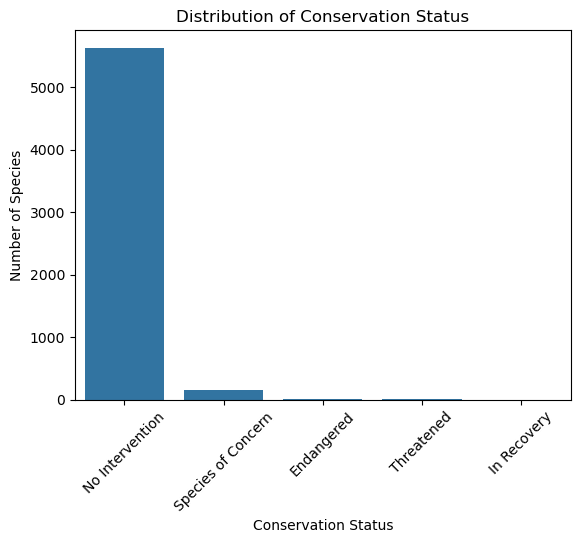

In [12]:
sns.countplot(data = species, x = "conservation_status", order = conservation_counts.index)

plt.title("Distribution of Conservation Status")
plt.xlabel("Conservation Status")
plt.ylabel("Number of Species")
plt.xticks(rotation = 45)
plt.show()

The results show that the vast majority of species (5,633 out of 5,824) are classified as “No Intervention.” There are 161 species of concern, while only 16 are endangered, 10 are threatened, and 4 are in recovery. The bar chart clearly highlights the large difference between species with no conservation concern and those with a conservation status. Overall, the data suggests that only a small proportion of recorded species require conservation intervention, with “Species of Concern” being the most common status among species requiring some form of conservation attention.

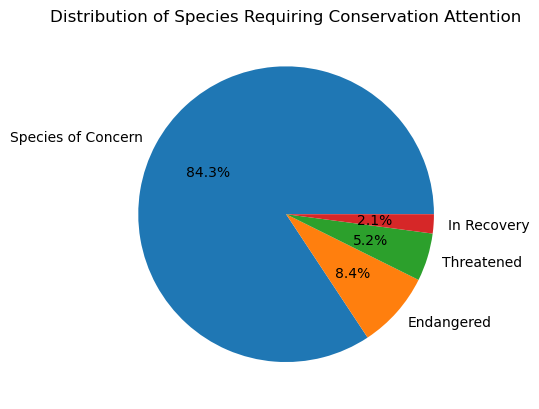

In [13]:
conservation_concern = conservation_counts.drop("No Intervention")
plt.pie(conservation_concern, labels = conservation_concern.index, autopct = "%1.1f%%")
plt.title("Distribution of Species Requiring Conservation Attention")
plt.show()


The bar chart visualisation is limited by the fact that a very large number of species are classified in a single category, “No Intervention,” making the smaller conservation categories difficult to compare. A pie chart that excludes the largest category can better illustrate the relative proportions of species receiving some form of conservation attention, making the differences between these smaller categories easier to interpret.

### Are certain types of species more likely to have a conservation concern?

In [14]:
conservation_by_category = pd.crosstab(species["category"], species["conservation_status"])
conservation_by_category

conservation_status,Endangered,In Recovery,No Intervention,Species of Concern,Threatened
category,,,,,
Amphibian,1,0,73,4,2
Bird,4,3,442,72,0
Fish,3,0,116,4,4
Mammal,7,1,176,28,2
Nonvascular Plant,0,0,328,5,0
Reptile,0,0,74,5,0
Vascular Plant,1,0,4424,43,2


The contingency table shows that birds and mammals have the highest numbers of species with conservation concerns, with 72 and 28 species respectively. Mammals also have the highest number of endangered species, with 7, while birds have the highest number of species in recovery, with 3. However, vascular plants have the largest number of species overall, so the raw counts alone do not show whether a category is more likely to have a conservation concern.

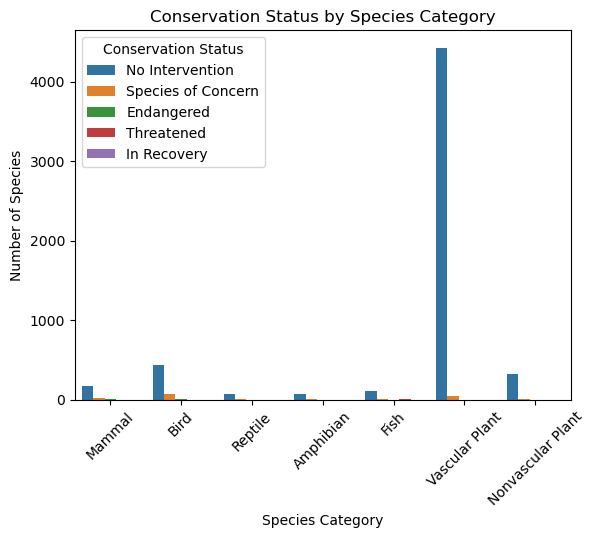

In [15]:
sns.countplot(data = species, x = "category",hue = "conservation_status")

plt.title("Conservation Status by Species Category")
plt.xlabel("Species Category")
plt.ylabel("Number of Species")
plt.xticks(rotation = 45)
plt.legend(title = "Conservation Status")
plt.show()

The countplot highlights differences in conservation status between species categories. Birds and mammals appear to have a greater number of species with conservation concerns than most other categories, while vascular plants have the largest overall number of species with no intervention. However, the large difference in the number of species between categories makes direct comparisons difficult, meaning the proportions within each category would provide a fairer comparison.

In [16]:
chi2, p, dof, expected = chi2_contingency(conservation_by_category)

print("Chi-squared statistic:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-squared statistic: 628.581965798279
p-value: 2.4551423165990194e-117
Degrees of freedom: 24


The chi-squared test produced a chi-squared statistic of 628.58, 24 degrees of freedom, and a p-value of approximately 2.46 × 10⁻¹¹⁷. The chi-squared statistic measures how much the observed distribution differs from what would be expected if species category and conservation status were unrelated, with the large value indicating a substantial difference. The 24 degrees of freedom result from the 7 species categories and 5 conservation statuses being compared and represent the number of independent comparisons used in the test. The extremely small p-value, which is far below the 0.05 significance level, indicates that the observed differences are statistically significant. Therefore, there is strong evidence that species category and conservation status are associated, suggesting that some types of species are more likely to have particular conservation statuses than others.

### Which species are observed most frequently?

In [17]:
species_observations = (observations.groupby("scientific_name")["observations"].sum().sort_values(ascending = False))
species_observations.head(10)

scientific_name
Streptopelia decaocto    1785
Holcus lanatus           1780
Castor canadensis        1725
Hypochaeris radicata     1720
Puma concolor            1711
Procyon lotor            1692
Columba livia            1653
Myotis lucifugus         1547
Bidens tripartita        1296
Oxalis dillenii          1276
Name: observations, dtype: int64

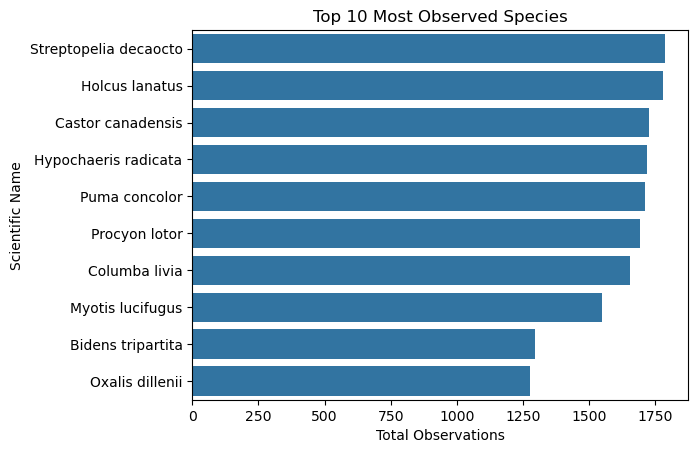

In [18]:
top_10_species = species_observations.head(10)
sns.barplot(x = top_10_species.values, y = top_10_species.index)
plt.title("Top 10 Most Observed Species")
plt.xlabel("Total Observations")
plt.ylabel("Scientific Name")
plt.show()

The results show that Streptopelia decaocto was the most frequently observed species, with 1,785 total observations, followed closely by Holcus lanatus with 1,780 and Castor canadensis with 1,725. The remaining species in the top 10 also had relatively high observation counts, although there is a larger drop between Myotis lucifugus (1,547) and Bidens tripartita (1,296). Overall, the chart shows that the most frequently observed species had considerably higher observation totals than the majority of species in the dataset, with Streptopelia decaocto having the highest total.

In [19]:
mean = species_observations.mean()
q1 = species_observations.quantile(0.25)
q3 = species_observations.quantile(0.75)
iqr = q3 - q1
print("Mean:", mean)
print("IQR:", iqr)

Mean: 598.2203573362209
IQR: 60.0


The mean total observations per species was 598.22, which is substantially lower than the observation counts shown in the bar chart. Additionally, the IQR was 60, indicating that the middle 50% of species have a relatively narrow range of total observations. This provides further context for the bar chart, as the top 10 species, with observation counts ranging from 1,276 to 1,785, are considerably higher than the typical species in the dataset.

### How do species observations differ between national parks?

In [20]:
park_observations = (observations.groupby("park_name")["observations"].mean().sort_values(ascending = False))
park_observations

park_name
Yellowstone National Park              247.864354
Yosemite National Park                 148.236951
Bryce National Park                     98.905391
Great Smoky Mountains National Park     74.144918
Name: observations, dtype: float64

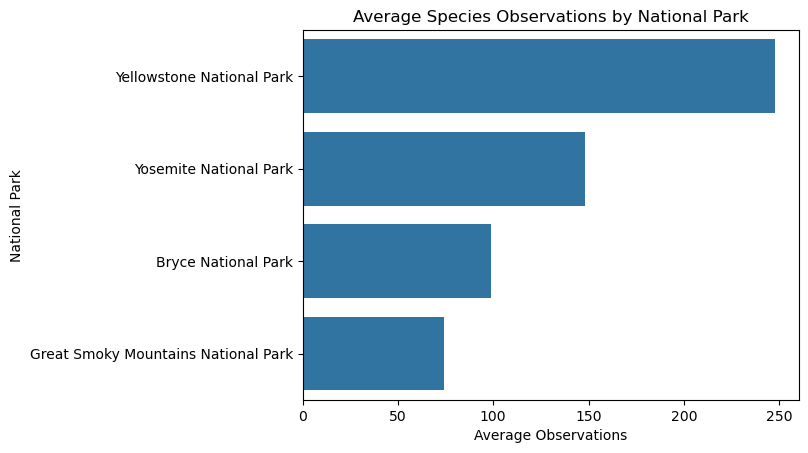

In [21]:
sns.barplot(x = park_observations.values, y = park_observations.index)
plt.title("Average Species Observations by National Park")
plt.xlabel("Average Observations")
plt.ylabel("National Park")
plt.show()

The average number of observations varies considerably between the four national parks. Yellowstone National Park has the highest average, with 247.86 observations per species, followed by Yosemite National Park with 148.24, Bryce National Park with 98.91, and Great Smoky Mountains National Park with 74.14. The bar plot clearly illustrates this difference, with Yellowstone having an average observation level substantially higher than the other three parks. Overall, the results suggest that species were observed more frequently in Yellowstone than in the other national parks.

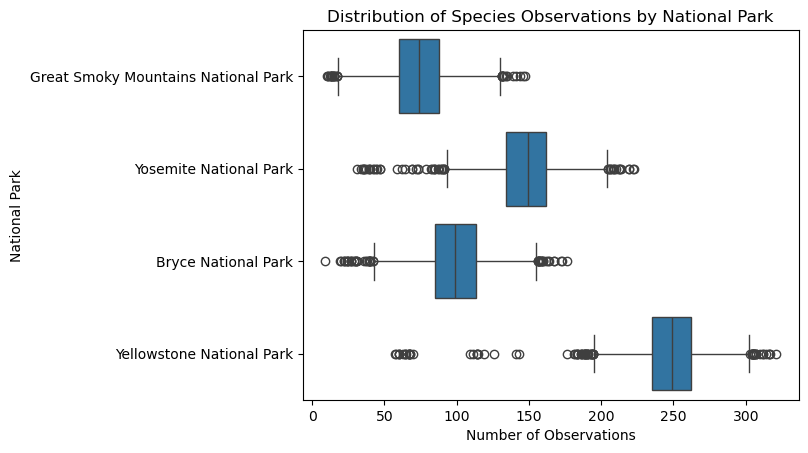

In [32]:
sns.boxplot(data = observations, x = "observations", y = "park_name")
plt.title("Distribution of Species Observations by National Park")
plt.xlabel("Number of Observations")
plt.ylabel("National Park")
plt.show()

The box plot provides additional context by showing the distribution and spread of observations within each national park rather than only the average. Yellowstone has the highest median and generally higher observation values, while Great Smoky Mountains has the lowest median. The distributions also contain a large number of outliers, showing that some species had substantially higher or lower observation counts than the typical species within their respective parks. This demonstrates why the box plot is useful alongside the mean and bar plot, as the averages alone do not show the variation or outliers within each park. One possible explanation for Yellowstone’s much higher average number of observations is its larger size compared to the other parks, although other factors such as habitat diversity, species abundance, environmental conditions, and sampling effort are also likely to influence observation numbers, as shown by Great Smoky Mountains having a larger area than Bryce Canyon but a lower mean number of observations.